# Notebook 24b — Wu 2003 SBI Training: S-B3 Structure

Train and audit a reduced-scope neural posterior estimator on the **S-B3** observation framing.
`S-B3` reuses the `S-B` observation structure but narrows the fault scope to endogenous reactor and
column degradation only, with `z_A0_eff` treated as exogenous and fixed nominally.

**Training-data history (see HANDOFF.md):**
1. First attempt: trained directly on notebook 22b's scenario-and-replicate bank (12 discrete
   retained-scenario theta values, replicated with noise). Failed calibration completely
   (`min_ks_pvalue` ~1e-24 to 1e-68 across all seeds, 40-100% of posterior samples landing outside
   the prior support): SNPE needs a genuinely continuous training distribution, and a 12-point
   discrete bank is structurally the wrong training target for that, however it's tuned.
2. Second attempt: an in-notebook generator sampling `theta` from `truncated_lognormal_4d_sb3()`.
   This crashed on a 30-minute cell timeout before completing a single bank (no checkpointing had
   been added to that generator), and even if it had finished, the narrow lognormal prior
   under-covers the named-fault severities that matter for classification (`alpha`/`beta_r` down to
   3.2-3.7 log-sigma into its tail -- see the discussion that led to `mixed_wide_prior_4d_sb3`).
3. **Current design:** this notebook now *loads* the mixed-wide-prior bank generated by notebook
   22b's Section 6-8 (`alpha, beta_r ~ Uniform`; `eta_col, xi_reb ~` truncated lognormal) instead of
   generating its own data. This avoids duplicating generation logic/compute across two notebooks and
   reuses nb22b's checkpointed, ETA-reporting generator rather than a second, less robust copy of it.

**Contents:**
1. Load mixed-wide-prior training data (from notebook 22b)
2. Train a seed ensemble and score confirm-budget SBC
3. Simulation-Based Calibration (SBC) and coverage audit
4. Snapshot posteriors for key retained scenarios
5. W12 reduced-scope ambiguity plot
6. Save posterior
7. Marginal posterior means across retained scenarios
8. Final acceptance criteria

This notebook keeps calibration as the primary gate: no downstream posterior should be trusted if
the confirm-budget SBC and coverage checks fail.

In [1]:
import pathlib, pickle, sys, time, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats as scipy_stats

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

from sbi.inference import SNPE
from sbi.neural_nets import posterior_nn
import cstr_sbi.recycle.sb3 as sb3
sb3 = importlib.reload(sb3)
from cstr_sbi.recycle.sb3 import (
    SB3_PARAM_NAMES,
    PRIOR_LOW_SB3_4D,
    PRIOR_HIGH_SB3_4D,
    mixed_wide_prior_4d_sb3,
    list_closed_loop_sb3,
    deterministic_window_sb3,
    classify_fault_sb3,
)
from cstr_sbi.recycle.summaries import compute_summaries, N_SUMMARIES_SB

DATA = ROOT / 'data'
RESULTS = ROOT / 'results'; RESULTS.mkdir(exist_ok=True)
FIGURES = ROOT / 'figures'; FIGURES.mkdir(exist_ok=True)
SBI_LOGS = ROOT / 'sbi-logs'; SBI_LOGS.mkdir(exist_ok=True)
OI = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7']

# Mixed-wide-prior S-B3 training/SBC banks produced by notebook 22b's Section 6-8
# (alpha, beta_r ~ Uniform; eta_col, xi_reb ~ truncated lognormal). N_TRAIN here must match
# notebook 22b's N_TRAIN.

#MIXEDWIDE_TRAIN_PATH = DATA / 'wu2003_sbi_train_sb3_mixedwide_n5000.npz'
#MIXEDWIDE_SBC_REDUCED_PATH = RESULTS / '24b_sysII_sb3_mixedwide_sbc_set_n120.npz'
#MIXEDWIDE_SBC_CONFIRM_PATH = RESULTS / '24b_sysII_sb3_mixedwide_sbc_set_n400.npz'

MIXEDWIDE_TRAIN_PATH = DATA / 'wu2003_sbi_train_sb3_mixedwide_n5000.npz'
MIXEDWIDE_SBC_REDUCED_PATH = RESULTS / '24b_sysII_sb3_mixedwide_sbc_set_n120.npz'
MIXEDWIDE_SBC_CONFIRM_PATH = RESULTS / '24b_sysII_sb3_mixedwide_sbc_set_n400.npz'


N_POST = 200
SEEDS = [0, 1, 2, 3, 4]
ARCH, HIDDEN, TRANSFORMS = 'zuko_nsf', 60, 3
MAX_EPOCHS, STOP_AFTER_EPOCHS = 120, 12

print(f'SEEDS={SEEDS}, ARCH={ARCH} {HIDDEN}/{TRANSFORMS}, N_POST={N_POST}')
print(f'MIXEDWIDE_TRAIN_PATH={MIXEDWIDE_TRAIN_PATH.relative_to(ROOT)}')
print(f'MIXEDWIDE_SBC_REDUCED_PATH={MIXEDWIDE_SBC_REDUCED_PATH.relative_to(ROOT)}')
print(f'MIXEDWIDE_SBC_CONFIRM_PATH={MIXEDWIDE_SBC_CONFIRM_PATH.relative_to(ROOT)}')

SEEDS=[0, 1, 2, 3, 4], ARCH=zuko_nsf 60/3, N_POST=200
MIXEDWIDE_TRAIN_PATH=data/wu2003_sbi_train_sb3_mixedwide_n5000.npz
MIXEDWIDE_SBC_REDUCED_PATH=results/24b_sysII_sb3_mixedwide_sbc_set_n120.npz
MIXEDWIDE_SBC_CONFIRM_PATH=results/24b_sysII_sb3_mixedwide_sbc_set_n400.npz


## 1. Load Mixed-Wide-Prior Training Data (from notebook 22b)

Loads the continuous mixed-wide-prior bank generated by notebook 22b's Section 6-8:
`theta4 = [alpha, beta_r, eta_col, xi_reb]` with `alpha, beta_r ~ Uniform(low, high)` and
`eta_col, xi_reb ~` their existing narrow truncated-lognormal marginals. `SNPE` is given the exact
same `mixed_wide_prior_4d_sb3()` distribution as its `prior=` argument below, so training and
calibration both target this continuous distribution consistently.

In [2]:
def _load_bank(path, theta_key='thetas4'):
    if not path.exists():
        raise FileNotFoundError(
            f'{path.name} not found. Run notebook 22b (mixed-wide-prior branch, RUN_MIXEDWIDE_BRANCH=True) first.'
        )
    data = np.load(path)
    return np.asarray(data[theta_key], dtype=np.float32), np.asarray(data['summaries'], dtype=np.float32)

theta_train, summary_train = _load_bank(MIXEDWIDE_TRAIN_PATH)
theta_sbc_r, summary_sbc_r = _load_bank(MIXEDWIDE_SBC_REDUCED_PATH)
theta_sbc_c, summary_sbc_c = _load_bank(MIXEDWIDE_SBC_CONFIRM_PATH)
assert summary_train.shape[1] == N_SUMMARIES_SB == summary_sbc_r.shape[1] == summary_sbc_c.shape[1]

n_unique_theta = len(np.unique(theta_train, axis=0))
print(f'theta_train  : {theta_train.shape}, summary_train: {summary_train.shape}')
print(f'theta_sbc_r  : {theta_sbc_r.shape}')
print(f'theta_sbc_c  : {theta_sbc_c.shape}')
print(f'unique theta rows in training bank: {n_unique_theta} (expect close to {theta_train.shape[0]}: continuous prior)')
print()
print('=== Parameter ranges against the S-B3 box ===')
for idx, name in enumerate(SB3_PARAM_NAMES):
    kind = 'uniform' if idx in (0, 1) else 'lognormal'
    print(
        f'  {name:8s} ({kind:9s}): train [{theta_train[:, idx].min():.3f}, {theta_train[:, idx].max():.3f}] '
        f'within [{PRIOR_LOW_SB3_4D[idx]:.3f}, {PRIOR_HIGH_SB3_4D[idx]:.3f}]'
    )

theta_train  : (5000, 4), summary_train: (5000, 66)
theta_sbc_r  : (120, 4)
theta_sbc_c  : (400, 4)
unique theta rows in training bank: 5000 (expect close to 5000: continuous prior)

=== Parameter ranges against the S-B3 box ===
  alpha    (uniform  ): train [0.400, 1.200] within [0.400, 1.200]
  beta_r   (uniform  ): train [0.400, 1.200] within [0.400, 1.200]
  eta_col  (lognormal): train [0.719, 1.000] within [0.500, 1.000]
  xi_reb   (lognormal): train [0.561, 1.200] within [0.400, 1.200]


## 2. Train a Seed Ensemble and Score Confirm-Budget SBC

This replaces notebook 24b's original pilot configuration sweep (which swept `prior_kind` and
warm-start strategy across its own from-scratch generator) with a simpler seed ensemble on the fixed
mixed-wide-prior bank loaded above: there is no longer a data-generation choice to sweep in this
notebook, only the training seed. As in notebook 24, a single training run's SBC result is not
trusted on its own -- each seed is trained once, screened on the reduced SBC set, and every seed is
scored on the larger confirm SBC set before the best is selected.

In [3]:
def train_posterior_sb3(theta_train, summary_train, prior_4d, seed):
    torch.manual_seed(seed)
    inference = SNPE(prior=prior_4d, density_estimator=posterior_nn(model=ARCH, hidden_features=HIDDEN, num_transforms=TRANSFORMS))
    inference.append_simulations(torch.tensor(theta_train), torch.tensor(summary_train))
    t0 = time.time()
    trained = inference.train(max_num_epochs=MAX_EPOCHS, validation_fraction=0.1,
                              stop_after_epochs=STOP_AFTER_EPOCHS, show_train_summary=False)
    return inference.build_posterior(trained), time.time() - t0


def run_sbc_sb3(posterior, theta_set, summary_set, n_post, seed, label):
    torch.manual_seed(seed)
    ranks = {name: [] for name in SB3_PARAM_NAMES}
    hits90 = {name: 0 for name in SB3_PARAM_NAMES}
    widths90 = {name: [] for name in SB3_PARAM_NAMES}
    sample_seconds = []
    t0 = time.time()
    for i, (th, s) in enumerate(zip(theta_set, summary_set)):
        t_sample = time.time()
        with torch.no_grad():
            samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),
                                    show_progress_bars=False,
                                    reject_outside_prior=False).detach().cpu().numpy()
        sample_seconds.append(time.time() - t_sample)
        for k, name in enumerate(SB3_PARAM_NAMES):
            ranks[name].append(int(np.sum(samp[:, k] < th[k])))
            lo, hi = np.percentile(samp[:, k], [5, 95])
            widths90[name].append(float(hi - lo))
            if lo <= th[k] <= hi:
                hits90[name] += 1
        if (i + 1) % 50 == 0 or (i + 1) == len(theta_set):
            print(f'[{label}] {i+1}/{len(theta_set)} in {time.time()-t0:.0f}s', flush=True)
    out = {
        'n_sbc': int(len(theta_set)), 'n_post': int(n_post), 'sbc_wall_s': float(time.time() - t0),
        'sample_seconds_mean': float(np.mean(sample_seconds)),
        'sample_seconds_p95': float(np.percentile(sample_seconds, 95)),
        'sample_seconds_max': float(np.max(sample_seconds)),
    }
    for name in SB3_PARAM_NAMES:
        r = np.asarray(ranks[name], dtype=float)
        ks = scipy_stats.ks_1samp(r / n_post, scipy_stats.uniform.cdf)
        out[name] = {
            'ks_pvalue': float(ks.pvalue),
            'mean_rank_frac': float(r.mean() / n_post),
            'coverage_90': float(hits90[name] / len(theta_set)),
            'mean_ci_width_90': float(np.mean(widths90[name])),
        }
    out['min_ks_pvalue'] = min(out[name]['ks_pvalue'] for name in SB3_PARAM_NAMES)
    out['max_abs_rank_bias'] = max(abs(out[name]['mean_rank_frac'] - 0.5) for name in SB3_PARAM_NAMES)
    return out


def flatten_run(seed, train_wall_s, result, stage):
    row = {
        'stage': stage, 'seed': seed, 'train_wall_s': train_wall_s,
        'n_sbc': result['n_sbc'], 'n_post': result['n_post'], 'sbc_wall_s': result['sbc_wall_s'],
        'sample_seconds_mean': result['sample_seconds_mean'],
        'sample_seconds_p95': result['sample_seconds_p95'],
        'sample_seconds_max': result['sample_seconds_max'],
        'min_ks_pvalue': result['min_ks_pvalue'], 'max_abs_rank_bias': result['max_abs_rank_bias'],
    }
    for name in SB3_PARAM_NAMES:
        row[f'{name}_ks_pvalue'] = result[name]['ks_pvalue']
        row[f'{name}_mean_rank_frac'] = result[name]['mean_rank_frac']
        row[f'{name}_coverage_90'] = result[name]['coverage_90']
        row[f'{name}_mean_ci_width_90'] = result[name]['mean_ci_width_90']
    return row


prior_4d = mixed_wide_prior_4d_sb3()
reduced_rows, confirm_rows = [], []
best = None
for seed in SEEDS:
    posterior_path = SBI_LOGS / f'wu2003_posterior_sb3_seed{seed}.pkl'
    if posterior_path.exists():
        with open(posterior_path, 'rb') as f:
            payload = pickle.load(f)
        posterior = payload['posterior']
        train_wall_s = float(payload.get('train_wall_s', 0.0))
        print(f'loaded {posterior_path.name}')
    else:
        posterior, train_wall_s = train_posterior_sb3(theta_train, summary_train, prior_4d, seed)
        with open(posterior_path, 'wb') as f:
            pickle.dump({'posterior': posterior, 'train_wall_s': train_wall_s, 'seed': seed,
                         'structure': 'S-B3', 'bank': str(MIXEDWIDE_TRAIN_PATH)}, f)
        print(f'saved {posterior_path.name}')
    reduced = run_sbc_sb3(posterior, theta_sbc_r, summary_sbc_r, n_post=N_POST,
                          seed=247000 + seed, label=f'reduced seed{seed}')
    confirm = run_sbc_sb3(posterior, theta_sbc_c, summary_sbc_c, n_post=N_POST,
                          seed=248000 + seed, label=f'confirm seed{seed}')
    reduced_rows.append(flatten_run(seed, train_wall_s, reduced, 'reduced'))
    confirm_rows.append(flatten_run(seed, train_wall_s, confirm, 'confirm'))
    score = (confirm['min_ks_pvalue'], -confirm['max_abs_rank_bias'])
    if best is None or score > best['score']:
        best = {'score': score, 'posterior': posterior, 'seed': seed, 'train_wall_s': train_wall_s, 'confirm': confirm}

reduced_df = pd.DataFrame(reduced_rows)
confirm_df = pd.DataFrame(confirm_rows)
reduced_df.to_csv(RESULTS / f'24b_sb3_reduced_sbc_n{len(theta_sbc_r)}.csv', index=False)
confirm_df.to_csv(RESULTS / f'24b_sb3_confirm_sbc_n{len(theta_sbc_c)}.csv', index=False)
with open(SBI_LOGS / 'wu2003_posterior_sb3.pkl', 'wb') as f:
    pickle.dump({
        'posterior': best['posterior'], 'selected_seed': best['seed'], 'train_wall_s': best['train_wall_s'],
        'structure': 'S-B3', 'bank': str(MIXEDWIDE_TRAIN_PATH),
        'sbc_reduced_bank': str(MIXEDWIDE_SBC_REDUCED_PATH), 'sbc_confirm_bank': str(MIXEDWIDE_SBC_CONFIRM_PATH),
        'arch': ARCH, 'hidden_features': HIDDEN, 'num_transforms': TRANSFORMS,
    }, f)
print('selected best seed', best['seed'])

loaded wu2003_posterior_sb3_seed0.pkl


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 90.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 6.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 9.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


[reduced seed0] 50/120 in 1s


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 19.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 7.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 47.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 5.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 78.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


[reduced seed0] 100/120 in 1s


... (91 outputs left out)

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 14.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3963739614.py:21: UserWarning: 23.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


[confirm seed4] 350/400 in 2s


[confirm seed4] 400/400 in 3s


selected best seed 2


## 3. Simulation-Based Calibration (SBC) and Coverage Audit

Displays the confirm-budget SBC results across the seed ensemble and the per-parameter calibration
detail for the selected seed, mirroring notebook 24's SBC display section.

In [4]:
display_cols = ['seed', 'min_ks_pvalue', 'max_abs_rank_bias'] + [f'{name}_ks_pvalue' for name in SB3_PARAM_NAMES]
print('Confirm-budget SBC by seed:')
print(confirm_df[display_cols].sort_values('min_ks_pvalue', ascending=False).to_string(index=False))

best_seed = int(confirm_df.sort_values(['min_ks_pvalue', 'max_abs_rank_bias'], ascending=[False, True]).iloc[0]['seed'])
best_row = confirm_df[confirm_df['seed'] == best_seed].iloc[0]
print(f'\nChosen seed: {best_seed}')
print('Per-parameter calibration summary for chosen seed:')
for name in SB3_PARAM_NAMES:
    print(
        f"  {name:8s} KS p={best_row[f'{name}_ks_pvalue']:.4f} "
        f"mean_rank={best_row[f'{name}_mean_rank_frac']:.3f} "
        f"cov90={best_row[f'{name}_coverage_90']:.3f} "
        f"mean_width90={best_row[f'{name}_mean_ci_width_90']:.4f}"
    )

Confirm-budget SBC by seed:
 seed  min_ks_pvalue  max_abs_rank_bias  alpha_ks_pvalue  beta_r_ks_pvalue  eta_col_ks_pvalue  xi_reb_ks_pvalue
    2   7.262969e-05           0.053850         0.381461      3.174450e-01       7.262969e-05          0.008130
    0   1.777190e-05           0.081650         0.000018      5.308901e-01       1.127992e-02          0.015493
    4   1.089165e-05           0.052075         0.000011      5.308901e-01       4.097587e-03          0.065117
    3   8.437516e-14           0.113912         0.084196      8.437516e-14       1.089165e-05          0.000018
    1   1.121237e-18           0.143150         0.000619      2.106671e-02       1.121237e-18          0.015493

Chosen seed: 2
Per-parameter calibration summary for chosen seed:
  alpha    KS p=0.3815 mean_rank=0.489 cov90=0.875 mean_width90=0.0100
  beta_r   KS p=0.3174 mean_rank=0.525 cov90=0.840 mean_width90=0.0512
  eta_col  KS p=0.0001 mean_rank=0.554 cov90=0.880 mean_width90=0.0154
  xi_reb   KS p=0.00

## 4. Snapshot Posteriors for Key Retained Scenarios

This mirrors notebook 24's key-scenario posterior inspection, but only for the retained reduced
scope. The goal is to sanity-check whether the selected posterior behaves sensibly on a few reactor,
column, and compound cases before moving on.

In [5]:
key_names = ['W3_cat_severe', 'W7_col_eff_mild', 'W12_snowball_compound', 'W16_full_multi']
scenario_lookup = {sc.name: sc for sc in list_closed_loop_sb3()}
with open(SBI_LOGS / 'wu2003_posterior_sb3.pkl', 'rb') as f:
    prod = pickle.load(f)
posterior_sb3 = prod['posterior']

snap_rows = []
for name in key_names:
    sc = scenario_lookup[name]
    t_h, raw_obs = deterministic_window_sb3(sc)
    summary = compute_summaries(np.asarray(raw_obs), 'S-B', np.asarray(t_h))
    with torch.no_grad():
        samp = posterior_sb3.sample((400,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()
    pred = classify_fault_sb3(samp)
    snap_rows.append({'scenario': name, 'pred_class': pred['class'], **pred['means']})
pd.DataFrame(snap_rows)

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/3932237500.py:13: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior_sb3.sample((400,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


,scenario,pred_class,alpha,beta_r,eta_col,xi_reb
0,W3_cat_severe,reactor,0.727251,1.013855,1.041855,0.917488
1,W7_col_eff_mild,column,0.947505,1.185606,0.819854,0.961055
2,W12_snowball_compound,multi,0.808319,1.158692,0.838293,0.933154
3,W16_full_multi,multi,0.808116,0.927646,0.835950,0.824313


## 5. W12 Reduced-Scope Ambiguity Plot

Notebook 24 inspected the full W12 joint posterior because that scenario carries the headline
reactor/column ambiguity. The reduced-scope version keeps that role, but focuses on the retained 4-D
posterior over endogenous parameters only.

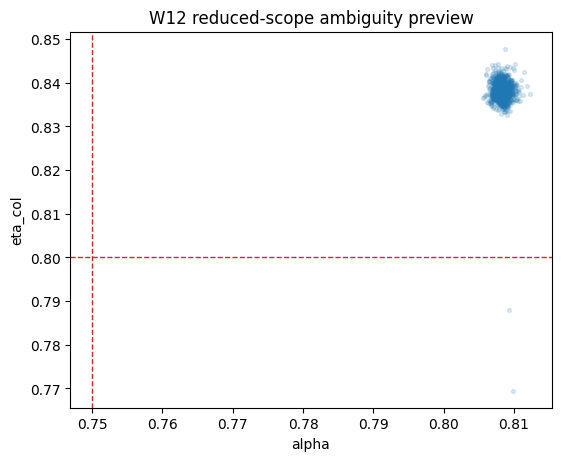

Saved nb24b_w12_reduced_scope.png


In [6]:
sc = scenario_lookup['W12_snowball_compound']
t_h, raw_obs = deterministic_window_sb3(sc)
summary = compute_summaries(np.asarray(raw_obs), 'S-B', np.asarray(t_h))
with torch.no_grad():
    samp_w12 = posterior_sb3.sample((1000,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()
fig, ax = plt.subplots(figsize=(5.5, 4.5), constrained_layout=True)
ax.scatter(samp_w12[:, 0], samp_w12[:, 2], s=8, alpha=0.15)
ax.axvline(float(sc.alpha), color='tab:red', ls='--', lw=1)
ax.axhline(float(sc.eta_col), color='tab:red', ls='--', lw=1)
ax.set_xlabel('alpha')
ax.set_ylabel('eta_col')
ax.set_title('W12 reduced-scope ambiguity preview')
plt.savefig(FIGURES / 'nb24b_w12_reduced_scope.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved nb24b_w12_reduced_scope.png')

## 6. Save Posterior

The best-seed posterior was already saved to `sbi-logs/wu2003_posterior_sb3.pkl` during Section 2's
ensemble loop. This section just confirms the saved provenance for a self-contained record.

In [7]:
with open(SBI_LOGS / 'wu2003_posterior_sb3.pkl', 'rb') as f:
    saved_prod = pickle.load(f)
print({k: saved_prod.get(k) for k in ['selected_seed', 'structure', 'bank', 'train_wall_s', 'arch', 'hidden_features', 'num_transforms']})

{'selected_seed': 2, 'structure': 'S-B3', 'bank': '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/data/wu2003_sbi_train_sb3_mixedwide_n5000.npz', 'train_wall_s': 16.266300916671753, 'arch': 'zuko_nsf', 'hidden_features': 60, 'num_transforms': 3}


## 7. Marginal Posterior Means Across Retained Scenarios

As in notebook 24, a final coarse sanity check is to look across the retained scenario catalogue and
ask whether posterior means move in the expected direction for the endogenous 4-D target.

In [8]:
marginal_rows = []
for sc in list_closed_loop_sb3():
    t_h, raw_obs = deterministic_window_sb3(sc)
    summary = compute_summaries(np.asarray(raw_obs), 'S-B', np.asarray(t_h))
    with torch.no_grad():
        samp = posterior_sb3.sample((300,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()
    marginal_rows.append({'scenario': sc.name, **{name: float(samp[:, i].mean()) for i, name in enumerate(SB3_PARAM_NAMES)}})
pd.DataFrame(marginal_rows)

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/4278138528.py:6: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior_sb3.sample((300,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/4278138528.py:6: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior_sb3.sample((300,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/4278138528.py:6: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior_sb3.sample((300,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/4278138528.py:6: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior_sb3.sample((300,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/4278138528.py:6: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior_sb3.sample((300,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_4849/4278138528.py:6: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior_sb3.sample((300,), x=torch.tensor(summary, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


,scenario,alpha,beta_r,eta_col,xi_reb
0,W1_healthy,1.043645,1.214655,0.965551,0.979025
1,W2_cat_mild,0.897103,1.101933,1.016491,0.917302
2,W3_cat_severe,0.727282,1.014105,1.041866,0.917593
3,W4_cat_threshold,0.657391,0.983611,1.036724,0.916621
4,W5_jacket_mild,1.052742,0.751770,0.940479,1.008030
5,W6_jacket_severe,1.068118,0.586772,0.944903,1.008150
6,W7_col_eff_mild,0.947463,1.185699,0.819903,0.961009
7,W9_reb_fouling,1.037047,1.257288,0.961017,0.725589
8,W11_reactor_combined,0.854856,0.855710,1.041815,0.923535
9,W12_snowball_compound,0.808266,1.158683,0.838333,0.933119


## 8. Final acceptance criteria

This notebook passes if:
1. the training bank is a continuous sample (not restricted to a handful of discrete theta values),
2. at least one seed clears `min_ks_pvalue > 0.05` on the confirm-budget SBC set,
3. all four parameters of the chosen seed have mean-rank fraction in `[0.45, 0.55]`,
4. all four parameters of the chosen seed have 90% coverage in `[0.80, 0.98]`.

If these fail, the reduced-scope problem is still not calibration-safe enough to support downstream
claims, even if classification later looks strong.

In [9]:
criteria = [
    ('training bank is a continuous sample (not a handful of discrete theta values)', n_unique_theta > 0.9 * theta_train.shape[0], f'{n_unique_theta}/{theta_train.shape[0]} unique theta rows'),
    ('at least one seed passes confirm min KS > 0.05', bool((confirm_df['min_ks_pvalue'] > 0.05).any()), f"n_pass={(confirm_df['min_ks_pvalue'] > 0.05).sum()}"),
    ('all chosen-seed mean ranks within [0.45, 0.55]', bool(all(0.45 <= best_row[f'{name}_mean_rank_frac'] <= 0.55 for name in SB3_PARAM_NAMES)), {name: float(best_row[f'{name}_mean_rank_frac']) for name in SB3_PARAM_NAMES}),
    ('all chosen-seed coverages within [0.80, 0.98]', bool(all(0.80 <= best_row[f'{name}_coverage_90'] <= 0.98 for name in SB3_PARAM_NAMES)), {name: float(best_row[f'{name}_coverage_90']) for name in SB3_PARAM_NAMES}),
]
for name, passed, value in criteria:
    print(f"{'PASS' if passed else 'FAIL'} | {name}: {value}")

PASS | training bank is a continuous sample (not a handful of discrete theta values): 5000/5000 unique theta rows
FAIL | at least one seed passes confirm min KS > 0.05: n_pass=0
FAIL | all chosen-seed mean ranks within [0.45, 0.55]: {'alpha': 0.489425, 'beta_r': 0.5251, 'eta_col': 0.55385, 'xi_reb': 0.52815}
PASS | all chosen-seed coverages within [0.80, 0.98]: {'alpha': 0.875, 'beta_r': 0.84, 'eta_col': 0.88, 'xi_reb': 0.8125}
